# How Have Recycling Rates for Paper, Plastic, Metal and Glass Changed in Singapore Over Time?

In [1]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 

In [2]:
recycling_df = pd.read_csv("singapore_recycling_rates_synthetic.csv")
recycling_df.head()

,Record_ID,Year,Month,Material,Waste_Generated_Tonnes,Waste_Recycled_Tonnes,Waste_Disposed_Tonnes,Recycling_Rate_Percent
0,1,2015,1,Paper,97224,48893,48331,50.29
1,2,2015,1,Plastic,70022,8175,61847,11.67
2,3,2015,1,Metal,17380,15581,1799,89.65
3,4,2015,1,Glass,49454,10071,39383,20.36
4,5,2015,2,Paper,100726,49939,50787,49.58


In [3]:
recycling_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Record_ID               500 non-null    int64  
 1   Year                    500 non-null    int64  
 2   Month                   500 non-null    int64  
 3   Material                500 non-null    object 
 4   Waste_Generated_Tonnes  500 non-null    int64  
 5   Waste_Recycled_Tonnes   500 non-null    int64  
 6   Waste_Disposed_Tonnes   500 non-null    int64  
 7   Recycling_Rate_Percent  500 non-null    float64
dtypes: float64(1), int64(6), object(1)
memory usage: 31.4+ KB


#### 1. Which material has the highest average recycling rate?

In [4]:
matl_avg_recycling_rate = recycling_df.groupby("Material")["Recycling_Rate_Percent"].mean().sort_values(ascending = False)
matl_avg_recycling_rate

Material
Metal      90.85920
Paper      40.96416
Glass      17.85888
Plastic     8.23432
Name: Recycling_Rate_Percent, dtype: float64

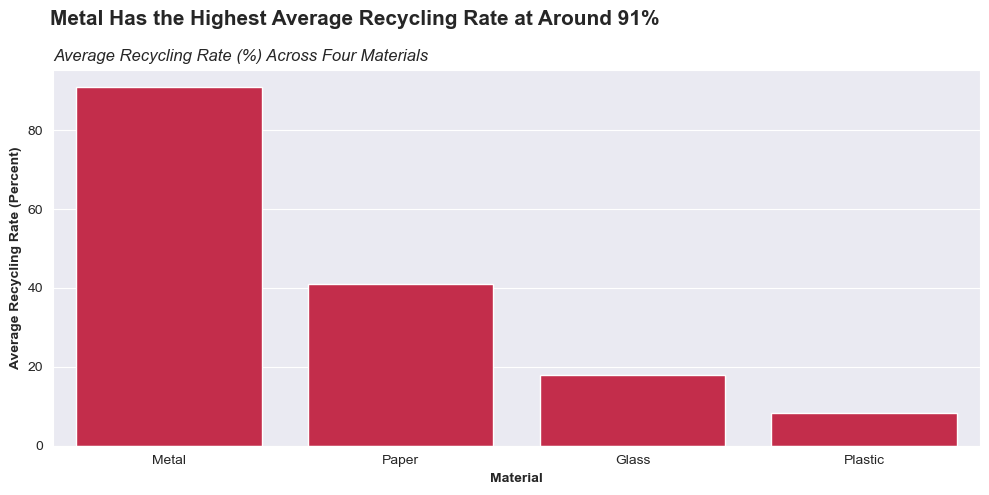

In [5]:
sns.set_style("darkgrid")
plt.figure(figsize = (10, 5))
sns.barplot(data = matl_avg_recycling_rate, color = "crimson")
plt.title("Average Recycling Rate (%) Across Four Materials", style = "italic", loc = "left")
plt.suptitle("Metal Has the Highest Average Recycling Rate at Around 91%",fontsize = 15, fontweight = "bold", x = 0.055, ha = "left")
plt.xlabel("Material", fontweight = "bold")
plt.ylabel("Average Recycling Rate (Percent)", fontweight = "bold")
plt.tight_layout()
plt.show()

#### 2. Which material contributes the most to total recycled waste?

In [6]:
matl_total_recycled_waste = recycling_df.groupby("Material")["Waste_Recycled_Tonnes"].sum().sort_values(ascending = False)
matl_total_recycled_waste

Material
Paper      4951004
Metal      2053410
Glass      1091974
Plastic     847891
Name: Waste_Recycled_Tonnes, dtype: int64

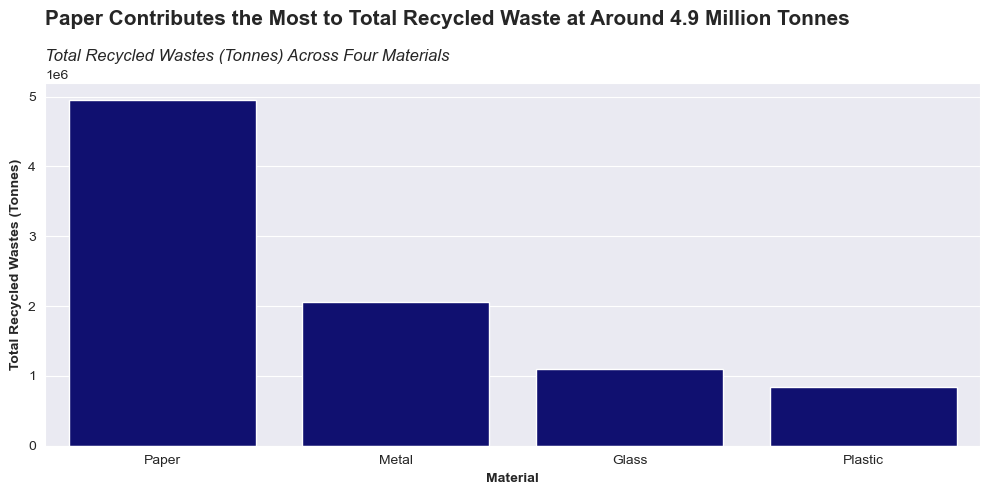

In [7]:
sns.set_style("darkgrid")
plt.figure(figsize = (10, 5))
sns.barplot(data = matl_total_recycled_waste, color = "navy")
plt.title("Total Recycled Wastes (Tonnes) Across Four Materials", style = "italic", loc = "left")
plt.suptitle("Paper Contributes the Most to Total Recycled Waste at Around 4.9 Million Tonnes",fontsize = 15, fontweight = "bold", x = 0.05, ha = "left")
plt.xlabel("Material", fontweight = "bold")
plt.ylabel("Total Recycled Wastes (Tonnes)", fontweight = "bold")
plt.tight_layout()
plt.show()

#### 3. How have recycling rates changed from 2015 to 2025?

In [36]:
avg_recycling_rates_yearly = recycling_df.groupby(["Year", "Material"])["Recycling_Rate_Percent"].mean().reset_index(name = "Avg Recycling Rate")
avg_recycling_rates_yearly.head()

,Year,Material,Avg Recycling Rate
0,2015,Glass,19.854167
1,2015,Metal,89.853333
2,2015,Paper,49.875833
3,2015,Plastic,10.212500
4,2016,Glass,19.400833


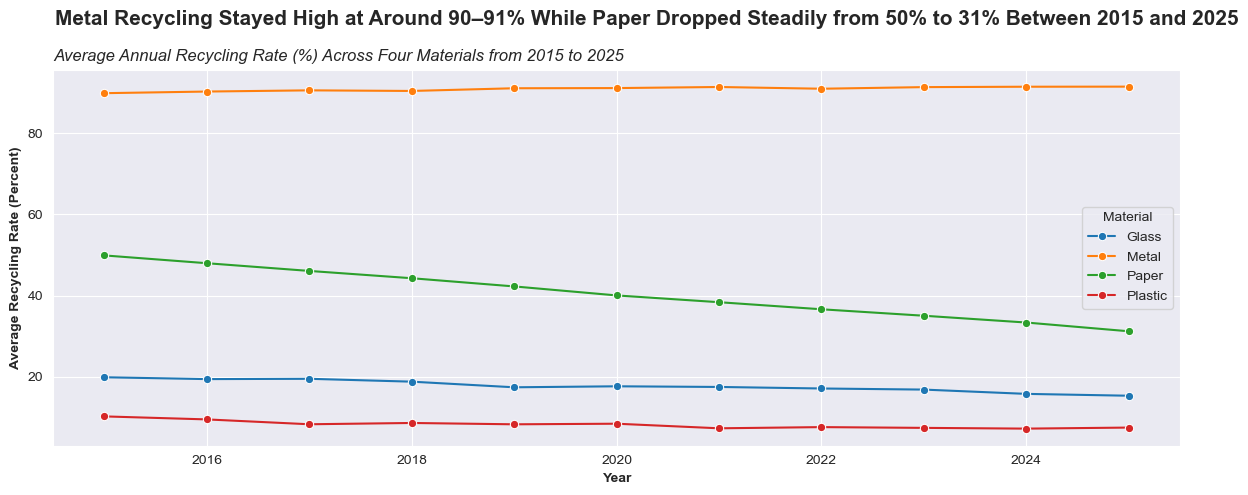

In [41]:
sns.set_style("darkgrid")
plt.figure(figsize = (12, 5))
sns.lineplot(data = avg_recycling_rates_yearly, x = "Year", y = "Avg Recycling Rate", hue = "Material", color = "brown", marker = 'o')
plt.title("Average Annual Recycling Rate (%) Across Four Materials from 2015 to 2025", style = "italic", loc = "left")
plt.suptitle("Metal Recycling Stayed High at Around 90–91% While Paper Dropped Steadily from 50% to 31% Between 2015 and 2025",fontsize = 15, fontweight = "bold", x = 0.05, ha = "left")
plt.xlabel("Year", fontweight = "bold")
plt.ylabel("Average Recycling Rate (Percent)", fontweight = "bold")
plt.tight_layout()
plt.show()

#### 4. How are recycling rates distributed across the four materials?

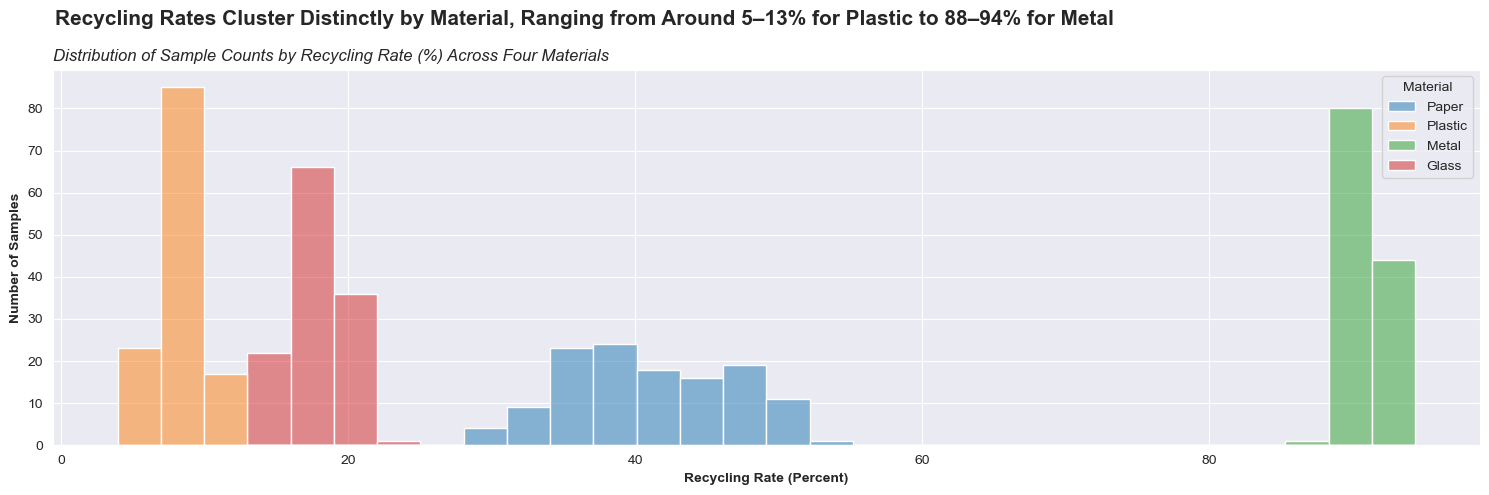

In [14]:
sns.set_style("darkgrid")
plt.figure(figsize = (15, 5))
sns.histplot(data = recycling_df, x = "Recycling_Rate_Percent", hue = "Material", bins = 30)
plt.title("Distribution of Sample Counts by Recycling Rate (%) Across Four Materials", style = "italic", loc = "left")
plt.suptitle("Recycling Rates Cluster Distinctly by Material, Ranging from Around 5–13% for Plastic to 88–94% for Metal",fontsize = 15, fontweight = "bold", x = 0.04, ha = "left")
plt.xlabel("Recycling Rate (Percent)", fontweight = "bold")
plt.ylabel("Number of Samples", fontweight = "bold")
plt.xticks(rotation = 0)
plt.tight_layout()
plt.show()

#### 5. Which material has the highest amount of waste disposed?

In [15]:
matl_total_disposed_waste = recycling_df.groupby("Material")["Waste_Disposed_Tonnes"].sum().sort_values(ascending = False)
matl_total_disposed_waste

Material
Plastic    9502096
Paper      7082119
Glass      5014154
Metal       206122
Name: Waste_Disposed_Tonnes, dtype: int64

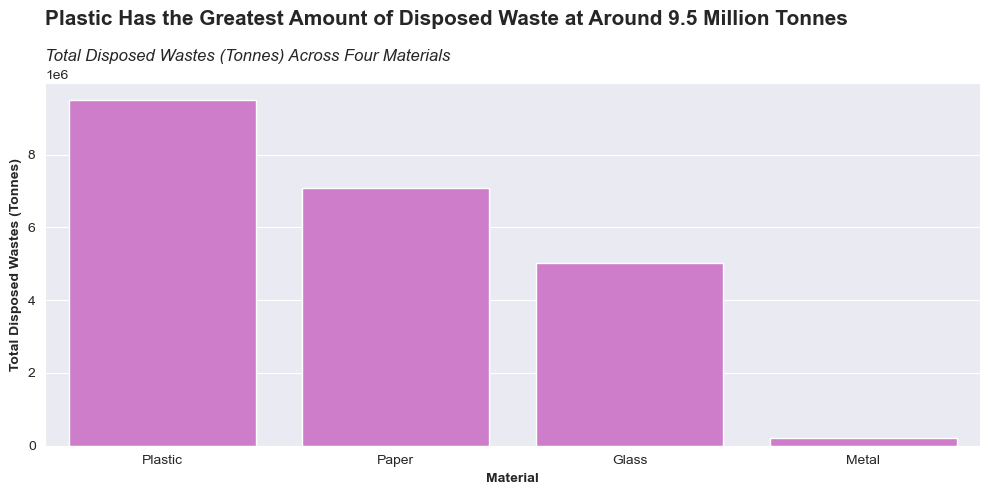

In [16]:
sns.set_style("darkgrid")
plt.figure(figsize = (10, 5))
sns.barplot(data = matl_total_disposed_waste, color = "orchid")
plt.title("Total Disposed Wastes (Tonnes) Across Four Materials", style = "italic", loc = "left")
plt.suptitle("Plastic Has the Greatest Amount of Disposed Waste at Around 9.5 Million Tonnes",fontsize = 15, fontweight = "bold", x = 0.05, ha = "left")
plt.xlabel("Material", fontweight = "bold")
plt.ylabel("Total Disposed Wastes (Tonnes)", fontweight = "bold")
plt.tight_layout()
plt.show()